# Demo: what the project has so far (Weeks 1–3)

A quick tour of the tooling for **AI-Based Multi-Object Tracking**, all on one simulated flight:

1. The experimental design: 108 flights, locked splits
2. Generating one flight: every object's motion plus labels
3. Rendered frames with labels drawn on top
4. Visibility over time: the scheduled occlusions
5. Recovery events, defined from truth alone
6. Scoring trackers with the event protocol and TrackEval (known-answer check)
7. What the detector will train on

Frames here come from the **toy renderer** (flat shapes, no Gazebo). It's for testing the pipeline only; study frames will come from Gazebo.
Runtime: about 1 minute. Run from the `notebooks/` folder of the repo (`pip install -r requirements-eval.txt matplotlib pandas`).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for p in ["scripts", "src/tracking_sim", "src/tracking_evaluation", "src/tracking_detector"]:
    sys.path.insert(0, str(ROOT / p))

import numpy as np, pandas as pd, yaml, cv2
import matplotlib.pyplot as plt
from tracking_sim.design import load_design, check_design
from tracking_sim.scenario import build_scenario
from tracking_sim.truth import compute_truth, truth_arrays
from tracking_sim.render_toy import render_frame
from tracking_sim.frames import apply_blur, blur_angles
from tracking_evaluation.audit import draw_truth
from tracking_evaluation.events import (extract_events, match_frames, score_events,
                                        infer_recovery_actions, score_actions, summarize)
from tracking_evaluation.mot_io import gt_rows, tracks_to_mot, run_trackeval
from tracking_detector.labels import classify_object

CFG   = yaml.safe_load((ROOT / "configs/scenario_design.yaml").read_text())
PROTO = yaml.safe_load((ROOT / "configs/event_protocol.yaml").read_text())
pd.set_option("display.width", 160)
print("repo:", ROOT)

repo: /home/claude/AI-Based-Multi-Object-Tracking


## 1. The experimental design

Every flight, its seed, conditions and split are fixed in `manifests/design.json`. The test subset is locked by a hash, so any change to it is detected.

In [2]:
design = load_design(ROOT / "manifests")
sealed = (ROOT / "manifests/test_manifest.sha256").read_text().split()[0]
print("design check:", check_design(design, sealed) or "OK (test manifest matches its seal)")

flights = pd.DataFrame(design["flights"])
print(f"{len(flights)} rendered flights -> {len(design['clips'])} clips (each flight gives a blur and a no-blur clip)\n")
display(pd.crosstab([flights.split, flights.layout], [flights.target_group, flights.occlusion_s], margins=True))

design check: OK (test manifest matches its seal)
108 rendered flights -> 216 clips (each flight gives a blur and a no-blur clip)



target_group ground         uav          All
occlusion_s     0.0 1.0 2.0 0.0 1.0 2.0     
split layout                                
test  L4          2   2   2   4   4   4   18
      L5          4   4   4   2   2   2   18
train L0          1   4   2   3   1   2   13
      L1          3   2   3   2   3   4   17
      L2          4   2   3   3   4   2   18
val   L3          4   4   4   4   4   4   24
All              18  18  18  18  18  18  108

Each split uses its own scene layouts (train L0–L2, val L3, test L4–L5), so validation and test always see unfamiliar scenes.

## 2. Generate one flight

UAVs, turning camera, 2-second occlusions. Generation is deterministic: the same seed always produces the same flight.

In [3]:
FLIGHT = "dev_uav_turning_occ20_s0"
fl = next(f for f in design["flights"] if f["flight_id"] == FLIGHT)
print(json.dumps(fl, indent=1))

sc = build_scenario(CFG, fl)          # every pose of every object at all 400 frames
truth = compute_truth(sc)             # per-frame labels (about 20 s)
FPS = CFG["clip"]["fps"]
print(f"\n{sc.n_frames} frames, {sc.stats['n_targets']} UAVs, scripted crossing pairs: {sc.stats['crossing_pairs']}")

{
 "flight_id": "dev_uav_turning_occ20_s0",
 "partition": "dev",
 "split": "train",
 "seed": 2850649694,
 "camera_motion": "turning",
 "occlusion_s": 2.0,
 "target_group": "uav",
 "layout": "L1"
}



400 frames, 4 UAVs, scripted crossing pairs: [[3, 4]]


In [4]:
print("Camera motion actually achieved:")
display(pd.Series({k: round(v, 1) for k, v in sc.stats.items() if isinstance(v, float)}).to_frame("value"))
print("Occlusion schedule (calibrated so each target is hidden for the nominal 2.0 s):")
display(pd.DataFrame(sc.schedule)[["slot", "target_id", "t_start", "t_end", "achieved_hidden_s", "panel_side_m"]])

Camera motion actually achieved:


,value
ang_rate_deg_s_median,16.0
ang_rate_deg_s_p95,34.9
speed_mps_median,3.2
speed_mps_max,4.5
accel_mps2_p95,1.9


Occlusion schedule (calibrated so each target is hidden for the nominal 2.0 s):


,slot,target_id,t_start,t_end,achieved_hidden_s,panel_side_m
0,0,2,4.3,6.3,2.0,1.0
1,1,1,9.9,11.9,2.0,1.0
2,2,4,14.1,16.1,2.0,1.0


## 3. Rendered frames with labels

Before, during and after the second scheduled occlusion. Coloured boxes are observable targets with *id visibility*. An ✕ marks a target hidden but still in view. The last panel is the same frame with the **motion-blur** condition applied.

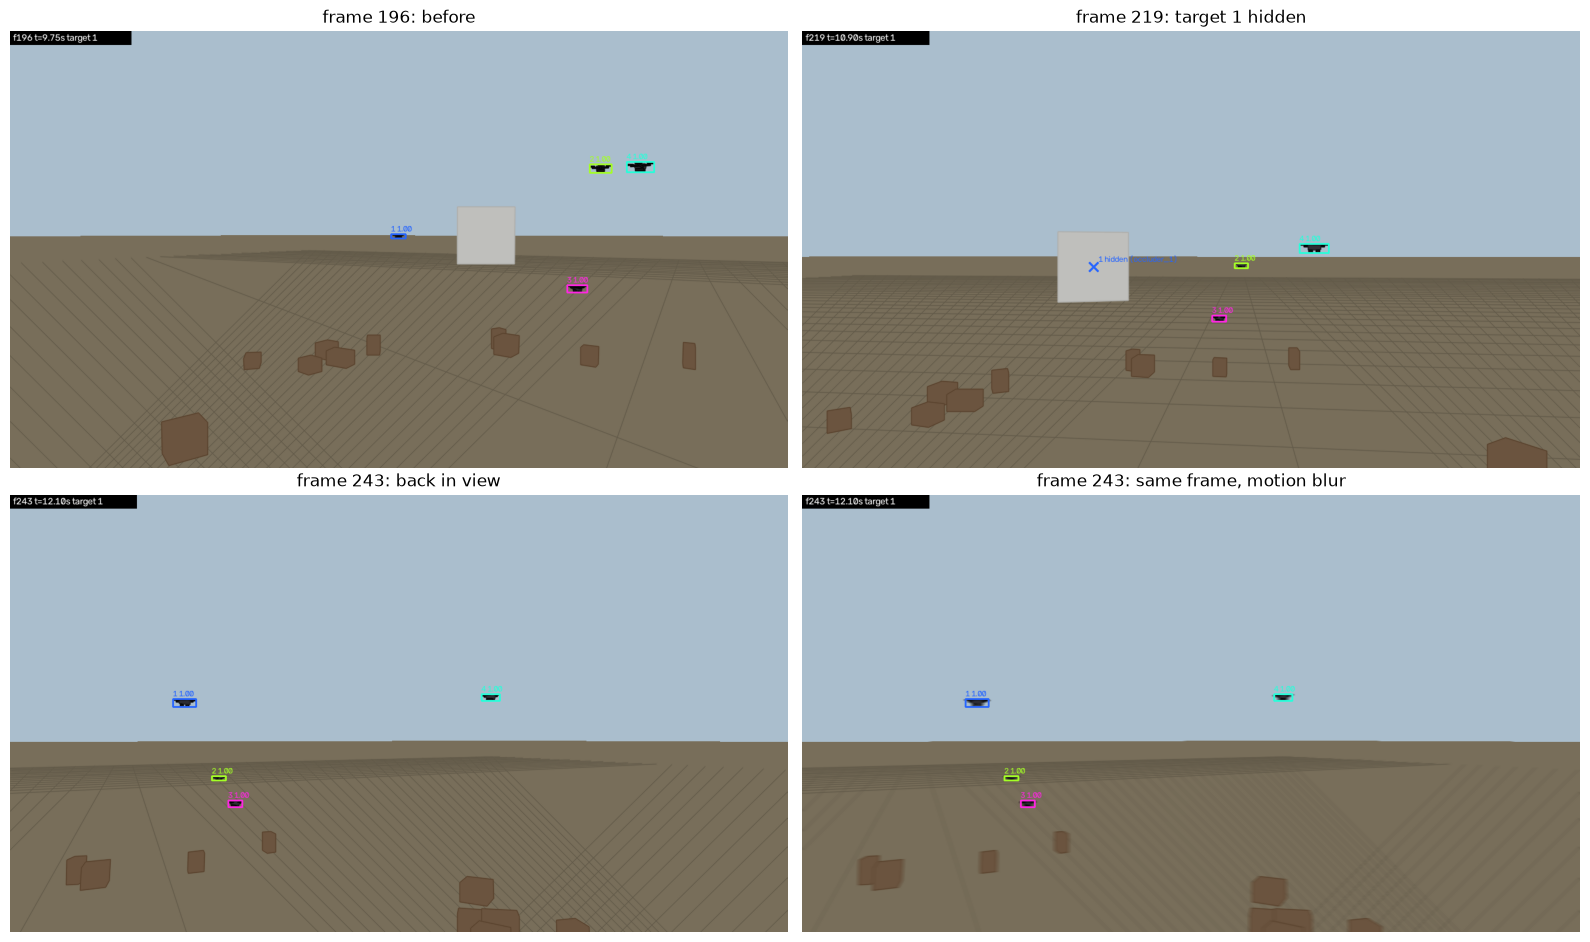

In [5]:
s = sc.schedule[1]
tid = s["target_id"]
f_before, f_mid, f_after = int(s["t_start"]*FPS) - 3, int((s["t_start"]+s["t_end"])/2*FPS), int(s["t_end"]*FPS) + 4
ground = tuple(int(c) for c in CFG["layouts"][fl["layout"]]["ground_rgb"][::-1])
angles = blur_angles(sc)

def show(f, blur=0):
    img, _ = render_frame(sc, f, ground)
    if blur: img = apply_blur(img, blur, angles[f])
    return cv2.cvtColor(draw_truth(img, truth[f], header=f"target {tid}"), cv2.COLOR_BGR2RGB)

panels = [(f_before, 0, "before"), (f_mid, 0, f"target {tid} hidden"), (f_after, 0, "back in view"),
          (f_after, CFG["factors"]["blur"]["motion"], "same frame, motion blur")]
fig, axes = plt.subplots(2, 2, figsize=(16, 9.5))
for ax, (f, b, title) in zip(axes.flat, panels):
    ax.imshow(show(f, b)); ax.set_title(f"frame {f+1}: {title}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Visibility over time

Visible fraction of each scheduled target across the flight. Below the dashed line (0.5) a target counts as **not observable**. Shaded bands are the scheduled occlusions. Dips outside the bands are natural occlusions from crossings and other drones.

Note target 2's **second** dip around 14–16 s: the panel scheduled for target 4 happens to hide it too. That's realistic collateral occlusion, and the event table below handles it on its own merits (2.25 s gap, so excluded as too long).

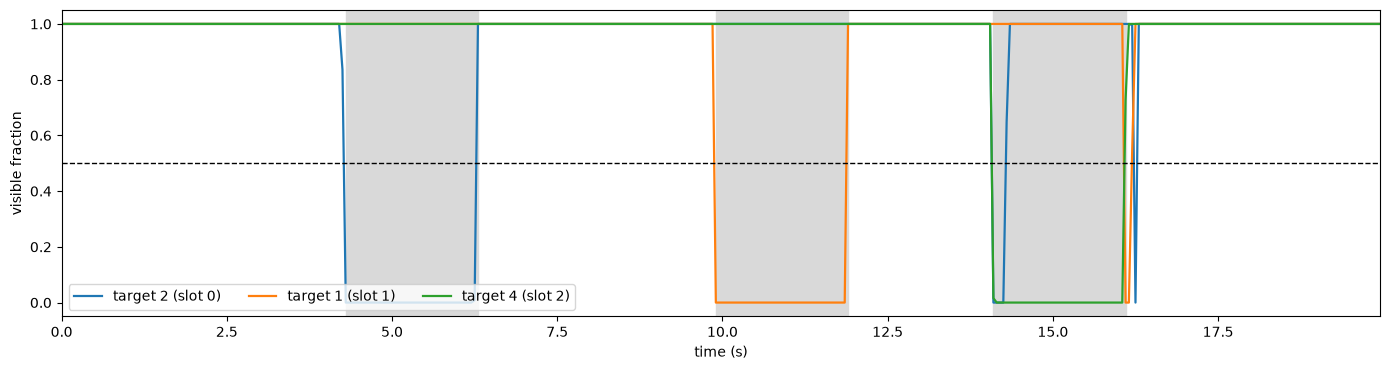

In [6]:
ids, vis, in_fov, min_side, boxes, occ_by = truth_arrays(truth)
t = sc.times
fig, ax = plt.subplots(figsize=(14, 3.8))
for s_ in sc.schedule:
    ax.axvspan(s_["t_start"], s_["t_end"], color="0.85")
    k = ids.index(s_["target_id"])
    ax.plot(t, vis[k], lw=1.6, label=f"target {s_['target_id']} (slot {s_['slot']})")
ax.axhline(PROTO["observability"]["vis_threshold"], ls="--", c="k", lw=1)
ax.set(xlabel="time (s)", ylabel="visible fraction", ylim=(-0.05, 1.05), xlim=(0, t[-1]))
ax.legend(loc="lower left", ncol=3); plt.tight_layout(); plt.show()

## 5. Recovery events, defined from truth alone

An event is a disappearance and reappearance of a target. It is **eligible** if the target was observable for ≥ 1 s before, the gap is ≤ 2 s and inside the field of view, and the target stays observable ≥ 1 s afterwards (plan §16, `configs/event_protocol.yaml`). Every tracker is scored against this same list.

In [7]:
event_list = extract_events(truth_arrays(truth), PROTO, FPS, FLIGHT, sc.schedule)
events = pd.DataFrame(event_list)
cols = ["target_id", "last_visible_frame", "reappear_frame", "gap_s", "cause", "scheduled", "eligible", "exclusion_reason"]
display(events[cols])
print(f"{events.eligible.sum()} eligible events: {(events.eligible & events.scheduled).sum()} from scheduled occluders, "
      f"{(events.eligible & ~events.scheduled).sum()} natural")

,target_id,last_visible_frame,reappear_frame,gap_s,cause,scheduled,eligible,exclusion_reason
0,1,129,135.0,0.25,size_or_out_of_view,False,True,NaN
1,1,198,239.0,2.00,occluder_1,True,True,NaN
2,2,86,127.0,2.00,occluder_0,True,True,NaN
3,2,260,306.0,2.25,occluder_2,False,False,gap_too_long
4,3,71,84.0,0.60,size_or_out_of_view,False,False,left_fov
5,3,349,NaN,2.55,target_4,False,False,boundary_post
6,4,282,323.0,2.00,occluder_2,True,True,NaN
7,4,385,391.0,0.25,size_or_out_of_view,False,False,boundary_post


4 eligible events: 3 from scheduled occluders, 1 natural


## 6. Scoring trackers (known-answer check)

Two **reference trackers built from ground truth**. They check the scoring, and are not baselines.
- `oracle_keep`: every target keeps its true id, so it should recover every event at 100% precision.
- `oracle_newid`: a target gets a new id each time it reappears, so it should recover nothing and show one identity switch per return.

Real trackers (ByteTrack, BoT-SORT, the heuristic control and the learned score) will be scored the same way from Week 4.

In [8]:
O = PROTO["observability"]
keep, newid, nxt, cur, was = {}, {}, 1000, {}, {}
for fr in truth:
    for o in fr["objects"]:
        ok = classify_object(o, O["vis_threshold"], O["min_box_side_px"]) == "target"
        if ok:
            if not was.get(o["id"]) and o["id"] in cur:
                nxt += 1; cur[o["id"]] = nxt
            cur.setdefault(o["id"], o["id"])
            keep.setdefault(fr["frame"], []).append((o["id"], tuple(o["visible_box"])))
            newid.setdefault(fr["frame"], []).append((cur[o["id"]], tuple(o["visible_box"])))
        was[o["id"]] = ok

eligible = [e for e in event_list if e["eligible"]]
rows = {}
for name, tbf in [("oracle_keep", keep), ("oracle_newid", newid)]:
    assign, inv = match_frames(truth, tbf, PROTO["scoring"]["match_iou"])
    s_ = summarize(score_events(eligible, assign, inv, PROTO, FPS),
                   score_actions(infer_recovery_actions(tbf, len(truth)), inv))
    rows[name] = {k: v for k, v in s_.items() if k != "failures"} | {"failures": s_["failures"]}

import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):   # TrackEval prints progress
    te = run_trackeval({FLIGHT: (gt_rows(truth, PROTO), len(truth))},
                       {"oracle_keep": {FLIGHT: tracks_to_mot(keep)}, "oracle_newid": {FLIGHT: tracks_to_mot(newid)}})
table = pd.DataFrame(rows).T.join(pd.DataFrame(te).T[["HOTA", "IDF1", "IDSW"]])
display(table[["HOTA", "IDF1", "IDSW", "eligible_events", "recovered", "recovery_recall",
               "recovery_actions", "recovery_precision", "failures"]].round(3))

,HOTA,IDF1,IDSW,eligible_events,recovered,recovery_recall,recovery_actions,recovery_precision,failures
oracle_keep,1.000,1.000,0.0,4,4,1.0,10,1.0,{}
oracle_newid,0.651,0.548,10.0,4,0,0.0,0,NaN,{'wrong_id_after_reappear': 4}


## 7. What the detector will train on

Training boxes are the visible part of clearly visible targets (vis ≥ 0.3). Hidden targets are never labelled. The size spread shows why UAVs are the hard case: most are under 32 px, the detector's "small" bins.

366 UAV training boxes from this flight (every 4th frame, before blur variants)


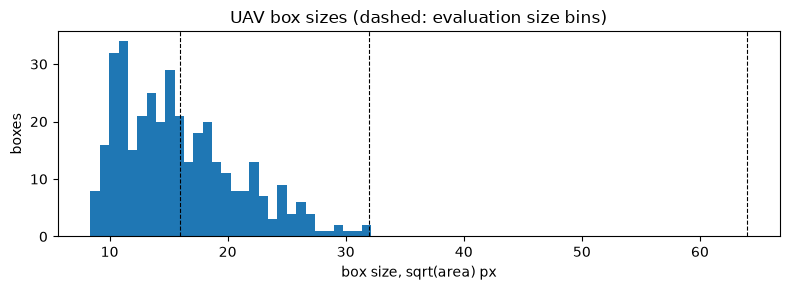

In [9]:
L = yaml.safe_load((ROOT / "configs/detector.yaml").read_text())["labels"]
sizes = [np.sqrt((o["visible_box"][2]-o["visible_box"][0]) * (o["visible_box"][3]-o["visible_box"][1]))
         for fr in truth[::L["frame_stride"]] for o in fr["objects"]
         if classify_object(o, L["min_vis"], L["min_box_side_px"], need_in_fov=False) == "target"]
print(f"{len(sizes)} UAV training boxes from this flight (every {L['frame_stride']}th frame, before blur variants)")
plt.figure(figsize=(8, 3)); plt.hist(sizes, bins=30)
for b in (16, 32, 64): plt.axvline(b, ls="--", c="k", lw=0.8)
plt.xlabel("box size, sqrt(area) px"); plt.ylabel("boxes"); plt.title("UAV box sizes (dashed: evaluation size bins)")
plt.tight_layout(); plt.show()

## Where this stands

| Built and tested | Still to do (on your machine) |
|---|---|
| Design, splits, locked test manifest | Verify Gazebo rendering (`docs/gazebo_verification.md`) |
| Scenario + label generation, calibrated occlusions | Manual label audit on Gazebo frames |
| Recovery-event rules + scoring, TrackEval adapter | Freeze configs; render all 108 flights; seal test data |
| Label audit tool, reference trackers | Fine-tune the detector on a GPU (960 vs 1280 px) |
| Detector export / train / evaluate / cache scripts | Related-work matrix, novelty note, advisor sign-off |

Next: Week 4, baselines (ByteTrack, BoT-SORT) and the matched heuristic recovery control, scored with the code above.